# Select metamodel goals in the AoI buffer ring

Workflow:

1. Load **AoI**, **land**, and all hindcast coordinate catalogs from `hindcasts-reduced`.
2. Build the **inland buffer ring**: `ring = (AoI − AoI.buffer(-d)) − land`.
3. Place **random spaced targets** inside the ring (open water), then number them **clockwise along the AoI boundary** (starting at the westernmost point).
4. For each target, snap to the **nearest node in every hindcast** catalog.
5. Compute **adaptive direction sectors** from the nearest **AoI boundary** point (NC convention).
6. Build the `goals` dict, plot, and save one JSON + one QGIS GeoPackage.

In [1]:
import json

import geopandas as gpd
import pandas as pd
from utils import hindcasts as hc
from utils import plotting as plot
from utils.config import CASE_DIR, PATHS, resolve

## Parameters

In [2]:
buffer_distance_m = 5_000.0
min_spacing_m = 50_000.0
sector_margin_deg = 5.0
random_seed = 42

geo_crs = "EPSG:4326"
work_crs = "EPSG:32702"  # UTM 2S — Samoa

hindcasts_dir = CASE_DIR.parent / "QGIS/HyWorld/hindcasts-reduced"
land_path = hindcasts_dir / "land.gpkg"
goals_out_path = resolve("inputs/goals/Samoa_goals.json")
goals_gpkg_path = resolve("inputs/goals/Samoa_goals.gpkg")

print(f"AoI       : {resolve(PATHS['aoi_file'])}")
print(f"hindcasts : {hindcasts_dir}")
print(f"land      : {land_path}")
print(f"json      : {goals_out_path}")
print(f"gpkg      : {goals_gpkg_path}")

AoI       : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/AoI_Polygons/Samoa_AoI.shp
hindcasts : /home/tausiaj/GitHub-GeoOcean/HyGloW/QGIS/HyWorld/hindcasts-reduced
land      : /home/tausiaj/GitHub-GeoOcean/HyGloW/QGIS/HyWorld/hindcasts-reduced/land.gpkg
json      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/goals/Samoa_goals.json
gpkg      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/goals/Samoa_goals.gpkg


## Load inputs

In [3]:
aoi = gpd.read_file(resolve(PATHS["aoi_file"])).to_crs(geo_crs)
land = hc.load_land(land_path)
catalogs = hc.load_catalogs(hindcasts_dir)

print(f"AoI catalogs: {list(catalogs)}")
for name, gdf in catalogs.items():
    print(f"  {name:6s}: {len(gdf):4d} points")

AoI catalogs: ['codec', 'era5', 'whacs']
  codec :   25 points
  era5  :   45 points
  whacs :  641 points


## Buffer ring and random targets

In [4]:
ring_poly, ring_gdf = hc.build_ring(aoi, land, buffer_distance_m, work_crs)
targets = hc.random_targets_in_ring(
    ring_poly,
    land,
    min_spacing_m=min_spacing_m,
    work_crs=work_crs,
    random_seed=random_seed,
)
targets = hc.sort_targets_along_aoi(
    targets,
    aoi,
    work_crs=work_crs,
    clockwise=True,  # False = CCW; None = shapefile vertex order
    start_at="west",  # goal 1 starts at the westernmost AoI point
)

print(
    f"ring area : {gpd.GeoDataFrame(geometry=[ring_poly], crs=geo_crs).to_crs(work_crs).geometry.area.iloc[0] / 1e6:,.1f} km²"
)
print(f"targets   : {len(targets)}  (min spacing = {min_spacing_m / 1000:g} km)")
targets

ring area : 4,276.7 km²
targets   : 11  (min spacing = 50 km)


,geometry,goal_id
0,POINT (-172.91645 -13.11364),1
1,POINT (-172.28888 -13.04542),2
2,POINT (-171.87081 -13.33024),3
3,POINT (-171.40712 -13.4658),4
4,POINT (-170.90188 -13.85437),5
5,POINT (-170.15757 -14.13132),6
6,POINT (-170.65579 -14.79573),7
7,POINT (-171.24775 -14.50634),8
8,POINT (-171.78905 -14.44281),9
9,POINT (-172.58205 -14.19846),10


## Build goals dict (target, angles, hindcast snaps)

In [5]:
sectors = hc.AoIRingSectors.from_aoi(aoi, work_crs)
goals = hc.build_goals_dict(
    targets,
    catalogs,
    sectors,
    work_crs=work_crs,
    margin_deg=sector_margin_deg,
)
boundary_snaps = hc.boundary_snaps(targets, sectors, work_crs=work_crs)

pd.DataFrame(
    [
        {
            "goal": k,
            "target_lon": v["target"]["longitude"],
            "target_lat": v["target"]["latitude"],
            "angles": v["angles"],
            **{f"{h}_fid": v["hindcast"][h]["fid"] for h in v["hindcast"]},
            **{f"{h}_dist_m": v["hindcast"][h]["distance_m"] for h in v["hindcast"]},
        }
        for k, v in goals.items()
    ]
)

,goal,target_lon,target_lat,angles,codec_fid,era5_fid,whacs_fid,codec_dist_m,era5_dist_m,whacs_dist_m
0,1,-172.916446,-13.113640,"[9.9, 228.0]",33048,148695,971045,14687.3,15500.2,6084.6
1,2,-172.288878,-13.045421,"[-35.5, 183.3]",42051,148696,971050,49512.1,23443.5,7999.0
2,3,-171.870814,-13.330243,"[-49.5, 139.6]",8701,149417,970817,53394.6,23413.1,3289.9
3,4,-171.407124,-13.465801,"[-17.5, 168.8]",38621,149418,970702,53610.3,10740.0,6678.2
4,5,-170.901882,-13.854368,"[36.9, 197.2]",33076,150139,970365,17450.0,19280.7,6390.7
5,6,-170.157575,-14.131324,"[-102.8, 118.5]",41928,150141,970143,45705.2,22371.1,7802.7
6,7,-170.655787,-14.795726,"[-180.4, 40.3]",33077,151580,969427,43843.7,28129.5,8530.6
7,8,-171.247747,-14.506341,"[133.5, 316.2]",42054,150859,969782,50279.5,26704.5,5200.9
8,9,-171.789048,-14.442813,"[160.0, 364.4]",8700,150857,969777,47683.9,23599.8,6557.0
9,10,-172.582050,-14.198460,"[169.9, 367.9]",8712,150136,970008,49071.7,23676.6,2575.6


## Map

/home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/utils/plotting.py:143: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(loc="upper right", fontsize=8)


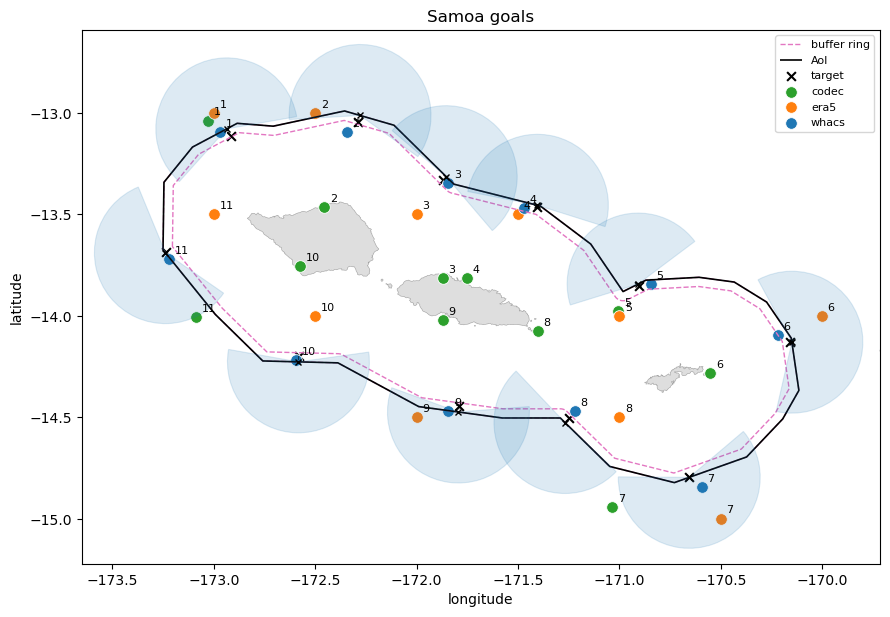

In [6]:
fig, ax = plot.plot_base_map(
    title="Samoa goals",
    show_topobathy=False,
    land=land,
    ring=ring_gdf,
)
plot.plot_sectors(targets, goals, boundary_snaps, ax)
targets.plot(ax=ax, color="black", markersize=40, marker="x", label="target")

plot.plot_points(
    hc.hindcast_snaps_gdf(goals),
    ax,
    color_col="catalog",
    label_col="goal_id",
    color_map=plot.HINDCAST_COLORS,
)

minx, miny, maxx, maxy = aoi.total_bounds
pad = 0.4
ax.set_xlim(minx - pad, maxx + pad)
ax.set_ylim(miny - pad, maxy + pad)
ax.set_aspect("equal", adjustable="box")

fig.tight_layout()

## Save goals JSON and QGIS GeoPackage

In [ ]:
goals_out_path.parent.mkdir(parents=True, exist_ok=True)

with goals_out_path.open("w", encoding="utf-8") as f:
    json.dump({"goals": goals}, f, indent=4)
    f.write("\n")

hc.save_goals_gpkg(goals, targets, boundary_snaps, goals_gpkg_path, ring=ring_gdf)

print(f"Wrote {len(goals)} goal(s) to:")
print(f"  {goals_out_path}")
print(f"  {goals_gpkg_path}")
print(
    "\nGPKG layers: targets, boundary_snaps, sectors, links, buffer_ring, "
    "codec, era5, whacs"
)
print(json.dumps({"goals": goals}, indent=4))

Wrote 11 goal(s) to:
  /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/goals/Samoa_goals.json
  /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/goals/Samoa_goals.gpkg

GPKG layers: targets, boundary_snaps, sectors, links, buffer_ring, codec, era5, whacs

Paste into Samoa.json:

{
    "goals": {
        "1": {
            "target": {
                "longitude": -172.916446,
                "latitude": -13.11364
            },
            "angles": [
                9.9,
                228.0
            ],
            "hindcast": {
                "codec": {
                    "fid": 33048,
                    "longitude": -173.02700000000002,
                    "latitude": -13.037,
                    "distance_m": 14687.3
                },
                "era5": {
                    "fid": 148695,
                    "longitude": -173.0,
                    "latitude": -13.0,
                    "distance_m": 15500.2
                },
                "whacs": {
            